# 02 · Main experiments

Logistic regression and random forest, uncalibrated vs Platt scaling vs isotonic regression, on both datasets and 10 seeds (`calib.experiments.run_main`). Calibrators are fitted on the calibration split; all metrics are on the test split.

Outputs: `results/metrics_all.csv`, `results/metrics_summary.csv`, `results/preds_{dataset}_seed0.npz`; table T1 (`figures/table_t1.tex`) and figures F1–F3.

In [1]:
# Configuration
SEEDS = range(10)
DATASETS = ("spambase", "adult")
RECOMPUTE = True  # False: load the cached results from results/ (about 10 minutes saved)

In [2]:
import logging

import pandas as pd

from calib import plotting
from calib.experiments import run_main
from calib.paths import RESULTS_DIR

# Progress messages from our own code only (other libraries stay at WARNING).
logging.basicConfig(level=logging.WARNING, format="%(name)s: %(message)s", force=True)
logging.getLogger("calib").setLevel(logging.INFO)
logging.getLogger("calib.data").setLevel(logging.WARNING)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)

In [3]:
if RECOMPUTE:
    results = run_main(datasets=DATASETS, seeds=SEEDS)
else:
    results = pd.read_csv(RESULTS_DIR / "metrics_all.csv")
print(f"{len(results)} rows: {results['dataset'].nunique()} datasets x "
      f"{results['seed'].nunique()} seeds x {results['model'].nunique()} models x "
      f"{results['method'].nunique()} methods")

calib.experiments: main: spambase seed 0 done in 18.6s


calib.experiments: main: spambase seed 1 done in 18.3s


calib.experiments: main: spambase seed 2 done in 18.0s


calib.experiments: main: spambase seed 3 done in 18.1s


calib.experiments: main: spambase seed 4 done in 18.0s


...

calib.experiments: main: adult seed 6 done in 37.0s


calib.experiments: main: adult seed 7 done in 52.0s


calib.experiments: main: adult seed 8 done in 52.7s


calib.experiments: main: adult seed 9 done in 57.1s


120 rows: 2 datasets x 10 seeds x 2 models x 3 methods


## T1 · Test metrics, mean ± std over seeds

Lower is better for log-loss, Brier score and ECE (10 equal-width bins); higher is better for accuracy and AUC. The std is the sample standard deviation over the seeds.

In [4]:
plotting.make_table_t1()

,Dataset,Model,Method,Accuracy,Log-loss,Brier score,ECE,ROC AUC
0,Spambase,LR,Uncalibrated,0.9205 ± 0.0067,0.2485 ± 0.0232,0.0639 ± 0.0041,0.0349 ± 0.0051,0.9674 ± 0.0045
1,Spambase,LR,Platt,0.9178 ± 0.0074,0.2481 ± 0.0178,0.0660 ± 0.0033,0.0413 ± 0.0085,0.9674 ± 0.0045
2,Spambase,LR,Isotonic,0.9213 ± 0.0066,0.3006 ± 0.0733,0.0623 ± 0.0042,0.0227 ± 0.0047,0.9660 ± 0.0049
3,Spambase,RF,Uncalibrated,0.9455 ± 0.0081,0.1726 ± 0.0143,0.0451 ± 0.0040,0.0533 ± 0.0101,0.9832 ± 0.0044
4,Spambase,RF,Platt,0.9457 ± 0.0084,0.1544 ± 0.0199,0.0407 ± 0.0042,0.0195 ± 0.0058,0.9832 ± 0.0044
5,Spambase,RF,Isotonic,0.9458 ± 0.0089,0.2035 ± 0.0778,0.0412 ± 0.0045,0.0170 ± 0.0063,0.9823 ± 0.0052
6,Adult,LR,Uncalibrated,0.8481 ± 0.0033,0.3253 ± 0.0041,0.1041 ± 0.0016,0.0109 ± 0.0031,0.9051 ± 0.0026
7,Adult,LR,Platt,0.8479 ± 0.0034,0.3253 ± 0.0041,0.1040 ± 0.0015,0.0110 ± 0.0031,0.9051 ± 0.0026
8,Adult,LR,Isotonic,0.8483 ± 0.0034,0.3292 ± 0.0046,0.1043 ± 0.0014,0.0109 ± 0.0039,0.9046 ± 0.0024
9,Adult,RF,Uncalibrated,0.8618 ± 0.0039,0.3106 ± 0.0047,0.0979 ± 0.0019,0.0244 ± 0.0043,0.9158 ± 0.0034


How many seeds does each calibrator improve on the uncalibrated model? (Count of seeds with a lower value.)

In [5]:
wide = results.pivot_table(index=["dataset", "model", "seed"], columns="method",
                           values=["log_loss", "brier", "ece"])
wins = {
    (metric, method): (wide[metric][method] < wide[metric]["uncalibrated"])
    .groupby(level=["dataset", "model"], sort=False).sum()
    for metric in ["log_loss", "brier", "ece"] for method in ["platt", "isotonic"]
}
pd.DataFrame(wins)

log_loss          brier            ece         
                   platt isotonic platt isotonic platt isotonic
dataset  model                                                 
adult    logreg        5        1     5        1     5        5
         rf           10        4    10       10    10       10
spambase logreg        6        3     1       10     2       10
         rf            9        3    10       10    10       10

## Fitted calibrators and tuned hyperparameters

In [6]:
platt = results[results["method"] == "platt"]
iso = results[results["method"] == "isotonic"]
pd.concat({
    "platt_a": platt.groupby(["dataset", "model"], sort=False)["platt_a"].agg(["mean", "min", "max"]),
    "platt_b": platt.groupby(["dataset", "model"], sort=False)["platt_b"].agg(["mean", "min", "max"]),
    "iso_blocks": iso.groupby(["dataset", "model"], sort=False)["iso_blocks"].agg(["mean", "min", "max"]),
}, axis=1)

platt_a                 platt_b                 iso_blocks            
                   mean     min     max    mean     min     max       mean   min   max
dataset  model                                                                        
spambase logreg  0.8444  0.6913  1.0458 -0.1069 -0.2068  0.1009       17.6  15.0  20.0
         rf      1.5260  1.3904  1.7825  0.0453 -0.1299  0.1651       15.0  13.0  17.0
adult    logreg  0.9866  0.9157  1.0436 -0.0217 -0.0948  0.0232       44.7  38.0  54.0
         rf      1.2288  1.1746  1.2908  0.1099  0.0748  0.1416       42.9  36.0  48.0

In [7]:
uncal = results[results["method"] == "uncalibrated"]
pd.concat({
    "C (LR)": uncal[uncal["model"] == "logreg"].groupby("dataset")["C"].value_counts(),
    "min_samples_leaf (RF)": uncal[uncal["model"] == "rf"].groupby("dataset")["min_samples_leaf"].value_counts(),
}).rename("n_seeds").to_frame()

n_seeds
                      dataset              
C (LR)                adult    0.1        5
                               1.0        5
                      spambase 1.0       10
min_samples_leaf (RF) adult    3.0       10
                      spambase 1.0        7
                               3.0        3

## Predictions of exactly 0 or 1

Isotonic regression outputs exactly 0 or 1 when a block of the calibration set is pure. A wrong prediction of exactly 0 or 1 costs −log(10⁻¹⁵) ≈ 34.5 in the clipped log-loss, so a handful of them can dominate the average. Mean per seed (test sets of 921 and 9,045 rows):

In [8]:
results.groupby(["dataset", "model", "method"], sort=False)[["n_exact_01", "n_exact_01_wrong"]].mean()

n_exact_01  n_exact_01_wrong
dataset  model  method                                    
spambase logreg uncalibrated         1.7               0.1
                platt                1.0               0.0
                isotonic           243.8               2.5
         rf     uncalibrated        74.8               0.0
                platt                0.0               0.0
                isotonic           283.1               1.7
adult    logreg uncalibrated         0.0               0.0
                platt                0.0               0.0
                isotonic           500.4               1.1
         rf     uncalibrated         0.7               0.0
                platt                0.0               0.0
                isotonic           989.0               2.2

## F1 · Reliability diagrams (seed 0, test set)

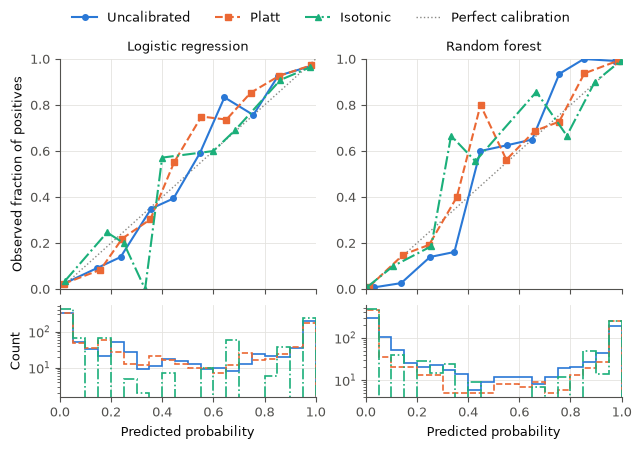

In [9]:
plotting.plot_reliability("spambase");

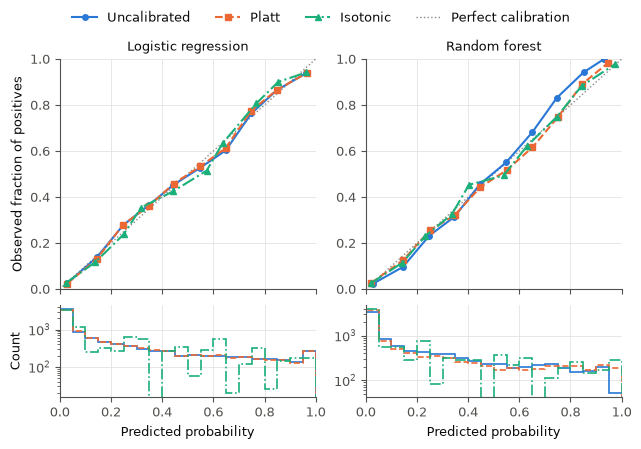

In [10]:
plotting.plot_reliability("adult");

## F2 · Learned correction maps (seed 0)

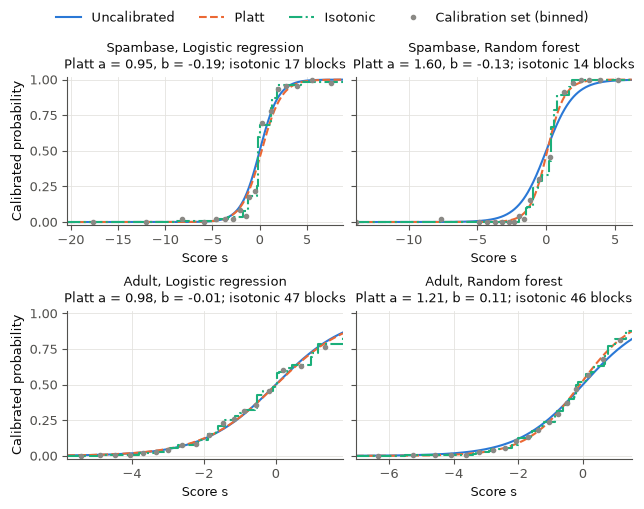

In [11]:
plotting.plot_correction_maps();

## F3 · Predicted probabilities before and after calibration (seed 0, test set)

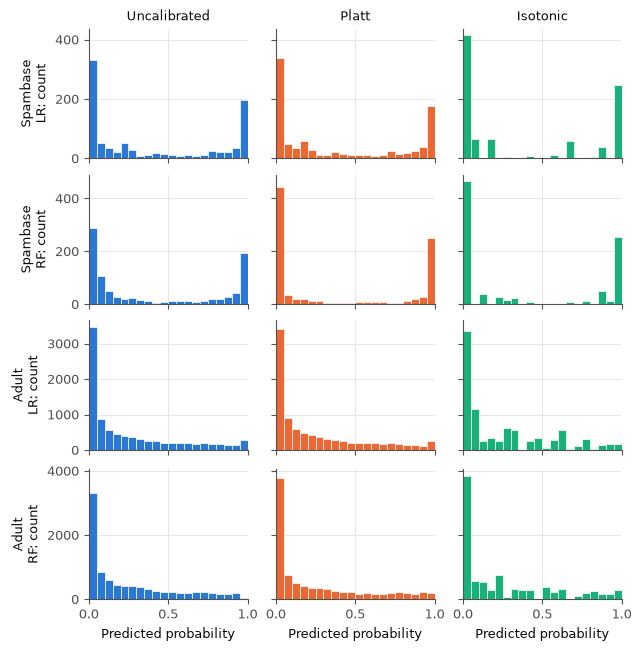

In [12]:
plotting.plot_histograms();

## Observations

**Random forest is miscalibrated, and both calibrators fix most of it.** In F1 the uncalibrated RF curve lies below the diagonal for low probabilities and above it for high ones: the averaged tree votes are pulled towards the middle. Platt and isotonic both lower RF's ECE and Brier score on every seed of both datasets (ECE −63% / −68% on Spambase, −51% / −58% on Adult, Platt / isotonic). Platt's slope is a > 1 for RF on every seed (mean 1.53 on Spambase, 1.23 on Adult): the correction stretches the probabilities away from 0.5, which F3 shows as mass moving to the ends of the histogram.

**Logistic regression is already close to calibrated.** Platt's fit is close to the identity (a ≈ 0.99, b ≈ −0.02 on Adult) and calibration changes LR's metrics by less than their seed-to-seed spread on Adult. On Spambase, isotonic lowers LR's ECE and Brier score on all 10 seeds, while Platt slightly increases them (a = 0.84 on average, i.e. it softens the probabilities, but this does not help on test). With 919 calibration examples, the differences for LR are of the order of the std.

**Log-loss tells a different story for isotonic.** Isotonic has the best ECE for RF but a worse mean log-loss than Platt in every case, and even than no calibration on both datasets. The cause is its exact 0/1 outputs: 1.1 to 2.5 wrong ones per seed on average. Their clipped cost (≈ 34.5 each, divided by the test size) is larger than the entire isotonic−Platt log-loss gap in all four dataset/model pairs. Log-loss punishes overconfidence without limit; Brier and ECE do not.

**Ranking and accuracy are preserved.** Platt is strictly increasing, so AUC is unchanged (the largest change, 5·10⁻⁶ on Spambase LR, comes from probabilities that round to exactly 1.0 in floating point). Isotonic is only non-decreasing: its blocks create ties, which lower AUC slightly (by at most 0.0043 on any seed). Mean accuracy changes by at most 0.003.

**Spambase vs Adult.** The calibration set is ten times larger on Adult (9,044 vs 919 rows): isotonic fits 43–45 blocks on average there against 15–18 on Spambase (F2), and all metrics vary much less across seeds. Spambase's RF miscalibration is also stronger (uncalibrated ECE 0.053 vs 0.024), as its predictions are more often unanimous tree votes.